# Predicting National Life Satisfaction with the World Happiness Report

This notebook predicts a country's **life satisfaction (Cantril "Life Ladder" score, 0–10)** from eight economic, social and emotional indicators.

**Data:** World Happiness Report panel data, 2005–2020 (166 countries, 1,949 country-year rows). The report is based on the Gallup World Poll and is published at [worldhappiness.report](https://worldhappiness.report).

**Workflow**
1. Load and clean the data
2. Explore it and select features
3. Train 5 models: 3 regression (KNN, Linear, Ridge) and 2 ensemble (AdaBoost, XGBoost)
4. Compare them and pick a winner

## 0. Setup

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import f_regression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import AdaBoostRegressor
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
SEED = 42

## 1. Load the data

In [2]:
df = pd.read_csv("world_happiness_report_2005_2020.csv")
print("Shape:", df.shape)
df.head()

Shape: (1949, 11)


,Country name,year,Life Ladder,Log GDP per capita,Social support,Healthy life expectancy at birth,Freedom to make life choices,Generosity,Perceptions of corruption,Positive affect,Negative affect
0,Afghanistan,2008,3.723590,7.370100,0.450662,50.799999,0.718114,0.167640,0.881686,0.517637,0.258195
1,Afghanistan,2009,4.401778,7.539972,0.552308,51.200001,0.678896,0.190099,0.850035,0.583926,0.237092
2,Afghanistan,2010,4.758381,7.646709,0.539075,51.599998,0.600127,0.120590,0.706766,0.618265,0.275324
3,Afghanistan,2011,3.831719,7.619532,0.521104,51.919998,0.495901,0.162427,0.731109,0.611387,0.267175
4,Afghanistan,2012,3.782938,7.705479,0.520637,52.240002,0.530935,0.236032,0.775620,0.710385,0.267919


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1949 entries, 0 to 1948
Data columns (total 11 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Country name                      1949 non-null   object 
 1   year                              1949 non-null   int64  
 2   Life Ladder                       1949 non-null   float64
 3   Log GDP per capita                1913 non-null   float64
 4   Social support                    1936 non-null   float64
 5   Healthy life expectancy at birth  1894 non-null   float64
 6   Freedom to make life choices      1917 non-null   float64
 7   Generosity                        1860 non-null   float64
 8   Perceptions of corruption         1839 non-null   float64
 9   Positive affect                   1927 non-null   float64
 10  Negative affect                   1933 non-null   float64
dtypes: float64(9), int64(1), object(1)
memory usage: 167.6+ KB


The target is `Life Ladder`. The other eight numeric columns are our candidate features, and `year` is only used for context. The long column names are shortened first.

In [4]:
df = df.rename(columns={
    "Country name": "Country",
    "year": "Year",
    "Life Ladder": "Life_Ladder",
    "Log GDP per capita": "Log_GDP",
    "Social support": "Social_Support",
    "Healthy life expectancy at birth": "Life_Expectancy",
    "Freedom to make life choices": "Freedom",
    "Perceptions of corruption": "Corruption",
    "Positive affect": "Positive_Affect",
    "Negative affect": "Negative_Affect",
})
features = ["Log_GDP", "Social_Support", "Life_Expectancy", "Freedom",
            "Generosity", "Corruption", "Positive_Affect", "Negative_Affect"]
target = "Life_Ladder"

## 2. Data cleaning

### 2.1 Duplicates and text formatting

In [5]:
df["Country"] = df["Country"].str.strip()
print("Fully duplicated rows      :", df.duplicated().sum())
print("Duplicate country-year pairs:", df.duplicated(["Country", "Year"]).sum())
df = df.drop_duplicates(["Country", "Year"]).reset_index(drop=True)

Fully duplicated rows      : 0
Duplicate country-year pairs: 0


### 2.2 Checking for impossible values
Scores like social support, freedom and corruption are proportions between 0 and 1, and the Life Ladder runs from 0 to 10.

In [6]:
bounds = {"Life_Ladder": (0, 10), "Social_Support": (0, 1), "Freedom": (0, 1), "Corruption": (0, 1),
          "Positive_Affect": (0, 1), "Negative_Affect": (0, 1), "Life_Expectancy": (30, 90)}

for col, (low, high) in bounds.items():
    bad = (~df[col].between(low, high) & df[col].notna()).sum()
    print(f"{col:16s} out of range: {bad}")

Life_Ladder      out of range: 0
Social_Support   out of range: 0
Freedom          out of range: 0
Corruption       out of range: 0
Positive_Affect  out of range: 0
Negative_Affect  out of range: 0
Life_Expectancy  out of range: 0


### 2.3 Outliers
I flag values outside 1.5 × IQR, but I keep them. These are real observations (for example, Haiti's life expectancy drops sharply in 2010 because of the earthquake), not data entry mistakes.

In [7]:
q1, q3 = df[features].quantile(0.25), df[features].quantile(0.75)
iqr = q3 - q1
outliers = ((df[features] < q1 - 1.5 * iqr) | (df[features] > q3 + 1.5 * iqr)).sum()
print(outliers.to_string())

Log_GDP              0
Social_Support      43
Life_Expectancy     15
Freedom             10
Generosity          36
Corruption         164
Positive_Affect      3
Negative_Affect     29


### 2.4 Missing values
Missing values only occur in the features, with `Corruption` and `Generosity` missing the most. Because this is panel data, a country's own typical value is a better fill than the world average. I fill each gap with that country's **median**, and fall back to the overall median if a country has no data for that column at all.

In [7]:
missing = df[features].isna().sum()
print("Missing before:\n", missing[missing > 0].to_string())

df[features] = df.groupby("Country")[features].transform(lambda s: s.fillna(s.median()))
df[features] = df[features].fillna(df[features].median())

print("\nMissing after:", df[features].isna().sum().sum())
print("Final shape:", df.shape)

Missing before:
 Log_GDP             36
Social_Support      13
Life_Expectancy     55
Freedom             32
Generosity          89
Corruption         110
Positive_Affect     22
Negative_Affect     16

Missing after: 0
Final shape: (1949, 11)


### 2.5 Save the cleaned dataset

In [8]:
df.to_csv("cleaned_world_happiness.csv", index=False)
df[[target] + features].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Life_Ladder,1949.0,5.47,1.12,2.38,4.64,5.39,6.28,8.02
Log_GDP,1949.0,9.37,1.15,6.64,8.47,9.46,10.35,11.65
Social_Support,1949.0,0.81,0.12,0.29,0.75,0.84,0.91,0.99
Life_Expectancy,1949.0,63.42,7.42,32.30,58.90,65.20,68.50,77.10
Freedom,1949.0,0.74,0.14,0.26,0.65,0.77,0.86,0.99
Generosity,1949.0,0.00,0.16,-0.34,-0.11,-0.03,0.09,0.70
Corruption,1949.0,0.74,0.19,0.04,0.68,0.80,0.87,0.98
Positive_Affect,1949.0,0.71,0.11,0.32,0.63,0.72,0.80,0.94
Negative_Affect,1949.0,0.27,0.08,0.08,0.21,0.26,0.32,0.70


## 3. Exploring the data

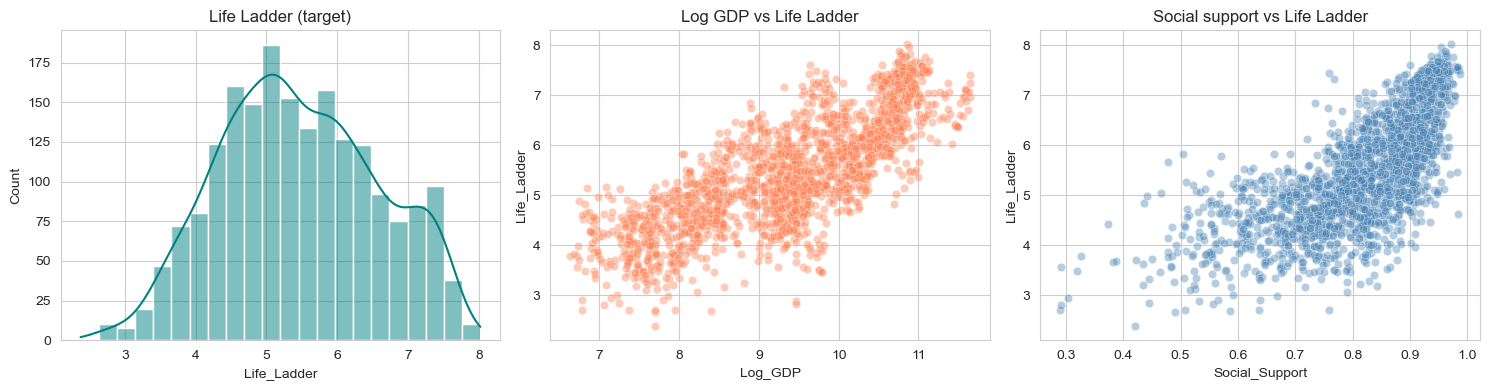

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df[target], kde=True, ax=axes[0], color="teal")
axes[0].set_title("Life Ladder (target)")
sns.scatterplot(data=df, x="Log_GDP", y=target, alpha=0.4, ax=axes[1], color="coral")
axes[1].set_title("Log GDP vs Life Ladder")
sns.scatterplot(data=df, x="Social_Support", y=target, alpha=0.4, ax=axes[2], color="steelblue")
axes[2].set_title("Social support vs Life Ladder")
plt.tight_layout()
plt.show()

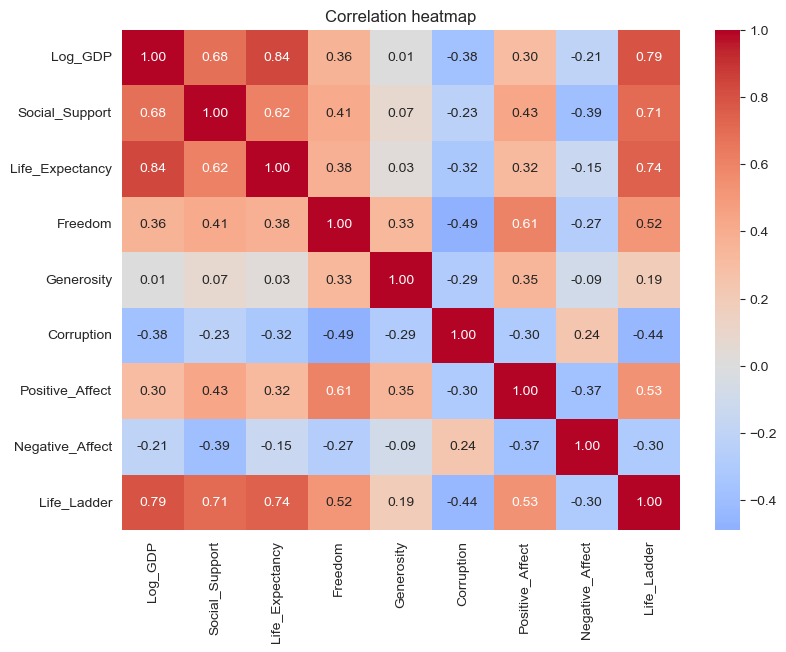

In [10]:
plt.figure(figsize=(9, 6.5))
sns.heatmap(df[features + [target]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
plt.show()

GDP, social support and life expectancy are strongly related to the Life Ladder, and also to each other, which is something to keep in mind when we get to the linear models.

## 4. Feature selection

Each feature is scored against the target with an F-test (`f_regression`). Features with a p-value above 0.05 don't show a reliable relationship with life satisfaction and would be dropped.

In [11]:
scores, pvalues = f_regression(df[features], df[target])
fs = pd.DataFrame({"Feature": features, "F_score": scores, "p_value": pvalues}).sort_values("F_score", ascending=False)
fs["Keep"] = fs["p_value"] < 0.05
fs.round(4).reset_index(drop=True)

,Feature,F_score,p_value,Keep
0,Log_GDP,3138.8575,0.0,True
1,Life_Expectancy,2410.7737,0.0,True
2,Social_Support,1957.5180,0.0,True
3,Positive_Affect,769.0936,0.0,True
4,Freedom,730.0933,0.0,True
5,Corruption,473.9855,0.0,True
6,Negative_Affect,187.9645,0.0,True
7,Generosity,75.6899,0.0,True


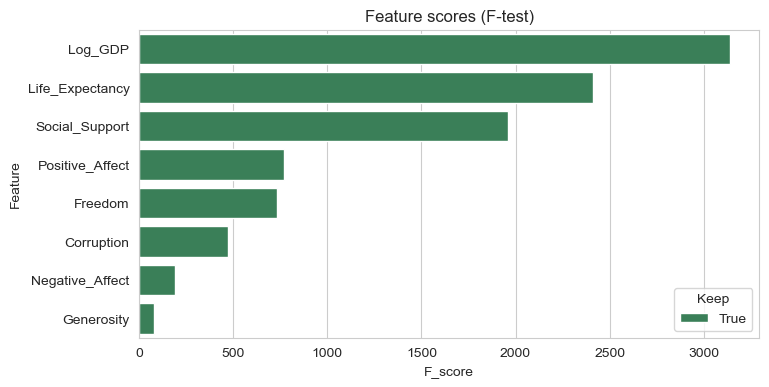

Selected features: ['Log_GDP', 'Life_Expectancy', 'Social_Support', 'Positive_Affect', 'Freedom', 'Corruption', 'Negative_Affect', 'Generosity']
Dropped: []


In [12]:
plt.figure(figsize=(8, 4))
sns.barplot(data=fs, x="F_score", y="Feature", hue="Keep", palette={True: "seagreen", False: "lightgray"}, dodge=False)
plt.title("Feature scores (F-test)")
plt.show()

selected = fs.loc[fs["Keep"], "Feature"].tolist()
print("Selected features:", selected)
print("Dropped:", fs.loc[~fs["Keep"], "Feature"].tolist())

## 5. Train / test split

Every country appears in many years. If I split rows at random, the same country would be in both train and test, and the models could just memorize each country. To avoid that, the split is done **by country**: 80% of countries for training, and the other 20% are completely unseen at test time. Cross-validation uses the same idea.

In [13]:
X, y, groups = df[selected], df[target], df["Country"]

splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, test_idx = next(splitter.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
g_train = groups.iloc[train_idx]

cv = GroupKFold(n_splits=5)
print("Train:", X_train.shape, "| countries:", g_train.nunique())
print("Test :", X_test.shape, "| countries:", groups.iloc[test_idx].nunique())

Train: (1551, 8) | countries: 132
Test : (398, 8) | countries: 34


A small helper keeps the evaluation identical for every model.

In [14]:
results, predictions, fitted = [], {}, {}

def evaluate(name, model):
    model.fit(X_train, y_train)
    pred_train, pred_test = model.predict(X_train), model.predict(X_test)
    results.append({
        "Model": name,
        "Train R2": r2_score(y_train, pred_train),
        "CV R2": cross_val_score(model, X_train, y_train, cv=cv, groups=g_train, scoring="r2").mean(),
        "Test R2": r2_score(y_test, pred_test),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, pred_test)),
        "Test MAE": mean_absolute_error(y_test, pred_test),
    })
    predictions[name], fitted[name] = pred_test, model
    print(pd.DataFrame(results).iloc[[-1]].round(4).to_string(index=False))

## 6. Regression models

### Model 1: K-Nearest Neighbors
Predicts a country-year's score from the average of the most similar country-years. Cross-validation picks the number of neighbors.

In [15]:
knn_pipe = Pipeline([("scale", StandardScaler()), ("knn", KNeighborsRegressor())])
knn_grid = GridSearchCV(knn_pipe, {"knn__n_neighbors": range(3, 31, 2), "knn__weights": ["uniform", "distance"]},
                        cv=cv, scoring="r2")
knn_grid.fit(X_train, y_train, groups=g_train)
print("Best parameters:", knn_grid.best_params_)
evaluate("KNN", knn_grid.best_estimator_)

Best parameters: {'knn__n_neighbors': 29, 'knn__weights': 'distance'}
Model  Train R2  CV R2  Test R2  Test RMSE  Test MAE
  KNN       1.0  0.744   0.5419     0.6706    0.5242


### Model 2: Linear Regression
The simplest baseline: one straight-line equation across all features.

In [16]:
evaluate("Linear Regression", Pipeline([("scale", StandardScaler()), ("lr", LinearRegression())]))

            Model  Train R2  CV R2  Test R2  Test RMSE  Test MAE
Linear Regression    0.7845 0.7516   0.6237     0.6078    0.4831


### Model 3: Ridge Regression
Linear regression with a penalty on large coefficients. Our features are correlated with each other, and Ridge copes with that better than plain linear regression.

In [17]:
ridge_pipe = Pipeline([("scale", StandardScaler()), ("ridge", Ridge())])
ridge_grid = GridSearchCV(ridge_pipe, {"ridge__alpha": [0.01, 0.1, 1, 10, 50, 100]}, cv=cv, scoring="r2")
ridge_grid.fit(X_train, y_train, groups=g_train)
print("Best parameters:", ridge_grid.best_params_)
evaluate("Ridge", ridge_grid.best_estimator_)

Best parameters: {'ridge__alpha': 50}
Model  Train R2  CV R2  Test R2  Test RMSE  Test MAE
Ridge    0.7842 0.7522   0.6317     0.6013    0.4799


## 7. Ensemble models

### Model 4: AdaBoost
Builds many shallow decision trees one after another. Each new tree focuses more on the samples the earlier trees got wrong.

In [18]:
ada_grid = GridSearchCV(
    AdaBoostRegressor(estimator=DecisionTreeRegressor(max_depth=4), random_state=SEED),
    {"n_estimators": [50, 100, 200], "learning_rate": [0.05, 0.1, 0.5, 1.0]},
    cv=cv, scoring="r2")
ada_grid.fit(X_train, y_train, groups=g_train)
print("Best parameters:", ada_grid.best_params_)
evaluate("AdaBoost", ada_grid.best_estimator_)

Best parameters: {'learning_rate': 0.05, 'n_estimators': 100}
   Model  Train R2  CV R2  Test R2  Test RMSE  Test MAE
AdaBoost    0.8546 0.7659   0.5862     0.6373    0.5035


   Model  Train R2  CV R2  Test R2  Test RMSE  Test MAE
AdaBoost    0.8546 0.7659   0.5862     0.6373    0.5035


### Model 5: XGBoost
Also builds trees one after another, but each tree is fitted to the remaining errors of the previous ones (gradient boosting), with built-in regularization to limit overfitting.

In [ ]:
xgb_grid = GridSearchCV(
    XGBRegressor(random_state=SEED, objective="reg:squarederror"),
    {"n_estimators": [100, 300], "max_depth": [2, 3, 5], "learning_rate": [0.03, 0.1], "subsample": [0.8, 1.0]},
    cv=cv, scoring="r2")
xgb_grid.fit(X_train, y_train, groups=g_train)
print("Best parameters:", xgb_grid.best_params_)
evaluate("XGBoost", xgb_grid.best_estimator_)

  Model  Train R2  CV R2  Test R2  Test RMSE  Test MAE
XGBoost    0.8977  0.778    0.645     0.5903    0.4715


## 8. Comparing all five models

**Train R2** vs **Test R2** shows overfitting (a big gap is a warning sign). **CV R2** is the average of 5-fold, country-grouped cross-validation on the training data, which is steadier than a single split.

In [ ]:
comparison = pd.DataFrame(results).sort_values("Test R2", ascending=False).reset_index(drop=True)
comparison.round(4)

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.barplot(data=comparison, x="Model", y="Test R2", ax=axes[0], palette="viridis")
axes[0].set_title("Test R2 (higher is better)")
sns.barplot(data=comparison, x="Model", y="Test RMSE", ax=axes[1], palette="magma")
axes[1].set_title("Test RMSE (lower is better)")
for ax in axes:
    ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharex=True, sharey=True)
lims = [y.min() - 0.2, y.max() + 0.2]
for ax, (name, pred) in zip(axes, predictions.items()):
    ax.scatter(y_test, pred, alpha=0.4, s=18)
    ax.plot(lims, lims, "r--", lw=1)
    ax.set_title(f"{name}\nR2 = {r2_score(y_test, pred):.3f}")
    ax.set_xlabel("Actual")
axes[0].set_ylabel("Predicted")
plt.tight_layout()
plt.show()

## 9. What drives life satisfaction?

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
coefs = pd.Series(fitted["Ridge"].named_steps["ridge"].coef_, index=selected).sort_values()
coefs.plot.barh(ax=axes[0], color="seagreen")
axes[0].set_title("Ridge coefficients (scaled features)")
for ax, name, color in zip(axes[1:], ["AdaBoost", "XGBoost"], ["purple", "darkorange"]):
    pd.Series(fitted[name].feature_importances_, index=selected).sort_values().plot.barh(ax=ax, color=color)
    ax.set_title(f"{name} feature importance")
plt.tight_layout()
plt.show()

## 10. Conclusion

**What I did:** loaded 1,949 real country-year observations from the World Happiness Report (2005–2020), checked for duplicates and impossible values (none found), filled the missing feature values using each country's own median, and scored all 8 features against life satisfaction. Every feature turned out to be statistically significant, so none were dropped. Then I trained 3 regression models and 2 ensembles with cross-validated tuning, splitting by country so the test countries were never seen during training.

**Model results:**

| Model | Type | CV R² | Test R² | Test RMSE |
|---|---|---|---|---|
| XGBoost | Ensemble | 0.778 | 0.645 | 0.590 |
| Ridge | Regression | 0.752 | 0.632 | 0.601 |
| Linear Regression | Regression | 0.752 | 0.624 | 0.608 |
| AdaBoost | Ensemble | 0.766 | 0.586 | 0.637 |
| KNN | Regression | 0.744 | 0.542 | 0.671 |

**What I take from this:**
- **XGBoost is the best model**, with the highest CV R² and the highest test R². On average it is off by about 0.47 points on the 0–10 scale (test MAE).
- **Ridge is a close second** and much simpler. Its edge over plain Linear Regression is small, which is expected with only 8 features.
- **KNN overfits the most.** It fits the training data perfectly (train R² = 1.0) but is the weakest on unseen countries.
- **AdaBoost is mixed.** It does well in cross-validation but drops on the test countries, so it is less reliable than XGBoost here.
- All models score lower on the test countries than in cross-validation. That is normal when the test set is a few unseen countries (34 here), and it shows how much harder it is to predict a country the model has never seen than a different year of a country it has.
- The feature rankings agree: GDP, life expectancy, social support and positive affect carry most of the signal.

**Caveats:** this data shows association, not cause. Life satisfaction is also self-reported, and some indicators (such as positive affect) are measured in the same survey as the target, so they partly reflect it rather than explain it. Missing values were filled, not observed, mostly for corruption and generosity.